# Kaggle Challenge：EDA

This notebook performs a systematic examination of `train.csv` using **pandas, NumPy, Matplotlib, and Seaborn**. It begins by assessing the data structure and quality, then proceeds to analyze missing values, the target variable `buy`, the relationship between users and concerts, numerical and categorical features, geographical distances, outliers, and validation strategies for modeling. Since the five rows associated with each user are interdependent, the training/validation split must be performed by grouping the data according to `user_id`.

**How ​​to run:** Place this notebook in the same folder as `train.csv` before executing it.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Current directory
train_path = Path("../data/raw/train_df.csv")
df = pd.read_csv(train_path)

display(df.head())
print(df.columns)

,row_id,user_id,music_app_user_id,age,education,spending_capacity_band,home_city,home_lat,home_lon,stated_favourite_genre,...,sale_opened_at,prediction_at,ticket_price,booking_fee,discount_pct,event_page_visits_7d,wishlisted,travel_search_city,travel_search_arrival,buy
0,R2F019957,U2CFDCAAD,M1B01D2D7,23,postgraduate,2,Nantes,47.218,-1.554,pop,...,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,75.0,9.50,0,0.0,1,NaN,NaN,0
1,R0804D93A,U1FC01010,M1B2C63CC,51,undergraduate,5,Bordeaux,44.838,-0.579,pop,...,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,85.0,10.10,0,3.0,0,NaN,NaN,1
2,R367FE81E,U0C605712,M3AEF638D,32,secondary,1,Lyon,45.764,4.835,classical,...,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,175.0,15.50,20,1.0,1,NaN,NaN,0
3,R344BBE29,U25D1DD8A,M00C580ED,24,secondary,2,Paris,48.857,2.352,jazz_funk,...,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,84.0,10.04,0,1.0,1,NaN,NaN,1
4,R004ABDEB,U1600BC92,M29AC37E6,21,secondary,3,Bordeaux,44.838,-0.579,NaN,...,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,95.0,10.70,0,0.0,0,Rennes,2026-12-28,1


Index(['row_id', 'user_id', 'music_app_user_id', 'age', 'education',
       'spending_capacity_band', 'home_city', 'home_lat', 'home_lon',
       'stated_favourite_genre', 'past_purchase_count', 'first_timer',
       'typical_ticket_spend', 'usual_booking_lead_days', 'concert_id',
       'artist_id', 'artist_name', 'genres', 'venue_city', 'venue_lat',
       'venue_lon', 'concert_at', 'sale_opened_at', 'prediction_at',
       'ticket_price', 'booking_fee', 'discount_pct', 'event_page_visits_7d',
       'wishlisted', 'travel_search_city', 'travel_search_arrival', 'buy'],
      dtype='str')


## 1.General

In [4]:
print("column_name_list：")
print(df.columns.tolist())
print("\ndatatype：")
display(df.dtypes.rename("dtype").to_frame())
print("\ninformation：")
df.info()

checks = {
    "row_id duplicated?": df["row_id"].duplicated().sum() if "row_id" in df else None,
    "user_id none?": df["user_id"].isna().sum() if "user_id" in df else None,
    "user_id + concert_id duplicated?": df.duplicated(["user_id", "concert_id"]).sum()
        if {"user_id", "concert_id"}.issubset(df.columns) else None,
    "Howmany_Users": df["user_id"].nunique() if "user_id" in df else None,
    "Howmany_Concerts": df["concert_id"].nunique() if "concert_id" in df else None,
}
display(pd.Series(checks, name="result").to_frame())

if "user_id" in df and "concert_id" in df:
    concerts_per_user = df.groupby("user_id")["concert_id"].nunique()
    display(concerts_per_user.value_counts().sort_index().rename_axis("concerts_per_user").to_frame("Users"))
    display(df.groupby("concert_id").agg(
        rows=("row_id", "size"), users=("user_id", "nunique")
    ).sort_index())

column_name_list：
['row_id', 'user_id', 'music_app_user_id', 'age', 'education', 'spending_capacity_band', 'home_city', 'home_lat', 'home_lon', 'stated_favourite_genre', 'past_purchase_count', 'first_timer', 'typical_ticket_spend', 'usual_booking_lead_days', 'concert_id', 'artist_id', 'artist_name', 'genres', 'venue_city', 'venue_lat', 'venue_lon', 'concert_at', 'sale_opened_at', 'prediction_at', 'ticket_price', 'booking_fee', 'discount_pct', 'event_page_visits_7d', 'wishlisted', 'travel_search_city', 'travel_search_arrival', 'buy']

datatype：


,dtype
row_id,str
user_id,str
music_app_user_id,str
age,int64
education,str
spending_capacity_band,int64
home_city,str
home_lat,float64
home_lon,float64
stated_favourite_genre,str



information：
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   row_id                   30000 non-null  str    
 1   user_id                  30000 non-null  str    
 2   music_app_user_id        28305 non-null  str    
 3   age                      30000 non-null  int64  
 4   education                30000 non-null  str    
 5   spending_capacity_band   30000 non-null  int64  
 6   home_city                30000 non-null  str    
 7   home_lat                 30000 non-null  float64
 8   home_lon                 30000 non-null  float64
 9   stated_favourite_genre   25375 non-null  str    
 10  past_purchase_count      30000 non-null  int64  
 11  first_timer              30000 non-null  int64  
 12  typical_ticket_spend     21760 non-null  float64
 13  usual_booking_lead_days  21760 non-null  float64
 14  concert_id         

,result
row_id duplicated?,0
user_id none?,0
user_id + concert_id duplicated?,0
Howmany_Users,6000
Howmany_Concerts,5


,Users
concerts_per_user,
5,6000


,rows,users
concert_id,,
C01,6000,6000
C02,6000,6000
C03,6000,6000
C04,6000,6000
C05,6000,6000


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   row_id                   30000 non-null  str    
 1   user_id                  30000 non-null  str    
 2   music_app_user_id        28305 non-null  str    
 3   age                      30000 non-null  int64  
 4   education                30000 non-null  str    
 5   spending_capacity_band   30000 non-null  int64  
 6   home_city                30000 non-null  str    
 7   home_lat                 30000 non-null  float64
 8   home_lon                 30000 non-null  float64
 9   stated_favourite_genre   25375 non-null  str    
 10  past_purchase_count      30000 non-null  int64  
 11  first_timer              30000 non-null  int64  
 12  typical_ticket_spend     21760 non-null  float64
 13  usual_booking_lead_days  21760 non-null  float64
 14  concert_id               30000 no

## 2.Date

Dates are currently typically read in as strings. Once converted to `datetime` objects, they can be used to calculate features such as "number of days until the performance."

In [7]:
date_cols = [c for c in ["concert_at", "sale_opened_at", "prediction_at", "travel_search_arrival"] if c in df]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce", utc=True)

print("Date column data types after conversion:")
display(df[date_cols].dtypes.to_frame("dtype"))
print("Valid value ranges for date fields:")
for col in date_cols:
    print(f"{col}: {df[col].min()} → {df[col].max()} | null {df[col].isna().sum():,}")

Date column data types after conversion:


,dtype
concert_at,"datetime64[us, UTC]"
sale_opened_at,"datetime64[us, UTC]"
prediction_at,"datetime64[us, UTC]"
travel_search_arrival,"datetime64[us, UTC]"


Valid value ranges for date fields:
concert_at: 2026-10-25 20:00:00+00:00 → 2026-12-28 20:00:00+00:00 | null 0
sale_opened_at: 2026-09-28 00:00:00+00:00 → 2026-09-28 00:00:00+00:00 | null 0
prediction_at: 2026-10-01 00:00:00+00:00 → 2026-10-01 00:00:00+00:00 | null 0
travel_search_arrival: 2026-10-07 00:00:00+00:00 → 2027-01-15 00:00:00+00:00 | null 22,496


## 4. Completely Duplicate Rows, Constant Columns, and Unique Values

In [13]:
print("Number of completely duplicate rows:", df.duplicated().sum())
constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print("A column with only one value: ", constant_cols)

unique_summary = pd.DataFrame({
    "n_unique": df.nunique(dropna=True),
    "unique_ratio": df.nunique(dropna=True) / len(df),
    "dtype": df.dtypes.astype(str),
}).sort_values("n_unique", ascending=False)
display(unique_summary)

Number of completely duplicate rows: 0
A column with only one value:  ['sale_opened_at', 'prediction_at']


,n_unique,unique_ratio,dtype
row_id,30000,1.000000,str
user_id,6000,0.200000,str
music_app_user_id,5661,0.188700,str
typical_ticket_spend,4078,0.135933,float64
usual_booking_lead_days,426,0.014200,float64
travel_search_arrival,93,0.003100,"datetime64[us, UTC]"
age,48,0.001600,int64
ticket_price,15,0.000500,float64
booking_fee,15,0.000500,float64
past_purchase_count,14,0.000467,int64


## 5. Target Variable `buy`: Class Proportions and Baseline

,count,share
buy,,
0,19914,0.6638
1,10086,0.3362


Overall purchase rate：33.62%


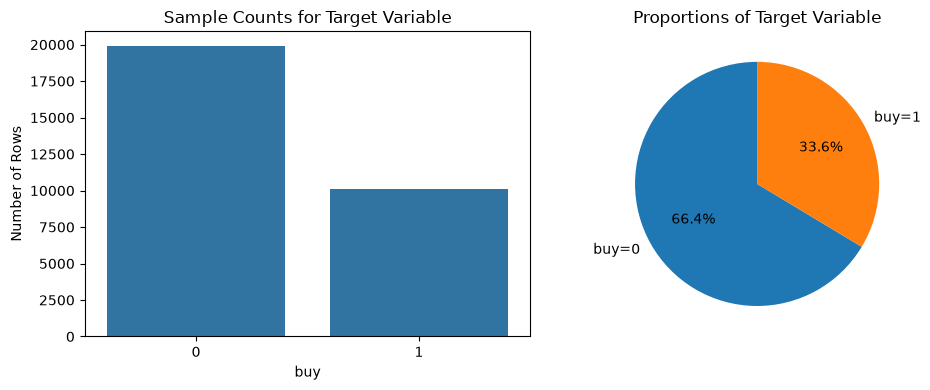

In [15]:
# This shows the dataset is imbalanced which needs to be taken into account
# while modeling
if "buy" in df:
    target_counts = df["buy"].value_counts(dropna=False).sort_index()
    target_rates = df["buy"].value_counts(normalize=True).sort_index()
    display(pd.DataFrame({"count": target_counts, "share": target_rates}).rename_axis("buy"))
    print(f"Overall purchase rate：{df['buy'].mean():.2%}")
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    sns.countplot(data=df, x="buy", ax=axes[0])
    axes[0].set_title("Sample Counts for Target Variable")
    axes[0].set_xlabel("buy")
    axes[0].set_ylabel("Number of Rows")
    axes[1].pie(target_counts.values, labels=[f"buy={i}" for i in target_counts.index], autopct="%1.1f%%", startangle=90)
    axes[1].set_title("Proportions of Target Variable")
    plt.tight_layout()
    plt.show()

## 6. Purchase Distribution: User-Level vs. Concert-Level

Since a single user may purchase tickets for multiple concerts, it is necessary to examine both the purchase rate for each individual concert and the number of concerts purchased per user.

,,rows,buyers,conversion_rate
concert_id,artist_name,,,
C03,Taylor Swift,6000,2329,38.82%
C05,SZA,6000,2188,36.47%
C01,Kendrick Lamar,6000,1975,32.92%
C02,Olivia Rodrigo,6000,1900,31.67%
C04,Tame Impala,6000,1694,28.23%


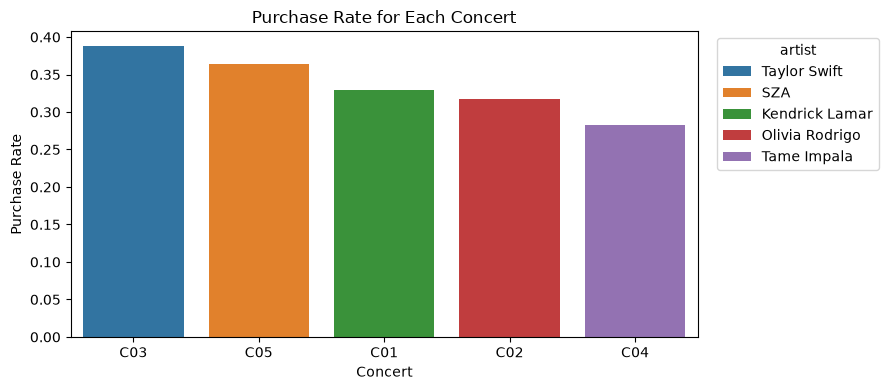

,Number of Users
Number of Concerts Purchased per User,
0,908
1,1909
2,1822
3,968
4,336
5,57


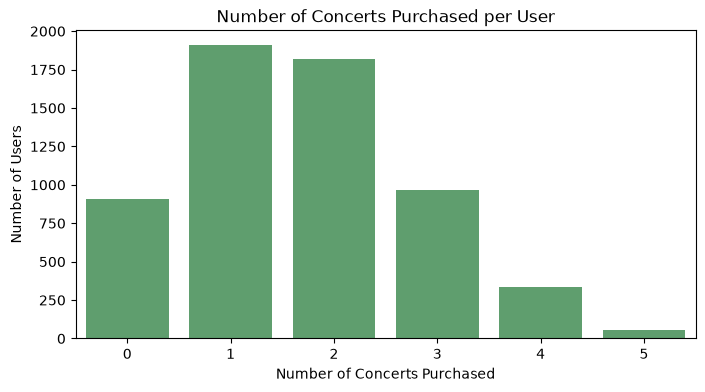

In [16]:
if {"concert_id", "buy"}.issubset(df.columns):
    concert_rates = df.groupby(["concert_id", "artist_name"], dropna=False).agg(
        rows=("buy", "size"), buyers=("buy", "sum"), conversion_rate=("buy", "mean")
    ).sort_values("conversion_rate", ascending=False)
    display(concert_rates.style.format({"conversion_rate": "{:.2%}"}))
    plt.figure(figsize=(9, 4))
    sns.barplot(data=concert_rates.reset_index(), x="concert_id", y="conversion_rate", hue="artist_name", dodge=False)
    plt.title("Purchase Rate for Each Concert")
    plt.ylabel("Purchase Rate")
    plt.xlabel("Concert")
    plt.legend(title="artist", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

if {"user_id", "buy"}.issubset(df.columns):
    buys_per_user = df.groupby("user_id")["buy"].sum()
    display(buys_per_user.value_counts().sort_index().rename_axis("Number of Concerts Purchased per User").to_frame("Number of Users"))
    plt.figure(figsize=(8, 4))
    sns.countplot(x=buys_per_user, color="#55A868")
    plt.title("Number of Concerts Purchased per User")
    plt.xlabel("Number of Concerts Purchased")
    plt.ylabel("Number of Users")
    plt.show()

## 7. Distribution of Numerical Featuresd.

In [17]:
df.describe()

,age,spending_capacity_band,home_lat,home_lon,past_purchase_count,first_timer,typical_ticket_spend,usual_booking_lead_days,venue_lat,venue_lon,ticket_price,booking_fee,discount_pct,event_page_visits_7d,wishlisted,buy
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,21760.000000,21760.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,29137.000000,30000.00000,30000.000000
mean,41.406667,2.979333,47.303203,1.988091,2.896000,0.274667,141.411673,62.709789,47.461400,1.622200,99.986608,10.999195,4.534667,0.606583,0.16220,0.336200
std,13.884153,1.437118,2.113600,2.589645,2.320423,0.446354,72.679219,46.384167,2.088592,2.359991,27.056185,1.623555,6.723960,0.798631,0.36864,0.472416
min,18.000000,1.000000,43.604000,-1.678000,0.000000,0.000000,20.870000,3.500000,44.838000,-1.554000,60.000000,8.600000,0.000000,0.000000,0.00000,0.000000
25%,30.000000,2.000000,45.764000,-0.579000,0.000000,0.000000,90.937500,31.500000,45.764000,-0.579000,76.000000,9.560000,0.000000,0.000000,0.00000,0.000000
50%,41.000000,3.000000,48.117000,2.352000,3.000000,0.000000,125.462500,50.000000,47.218000,2.352000,95.000000,10.700000,0.000000,0.000000,0.00000,0.000000
75%,53.000000,4.000000,48.857000,3.057000,5.000000,1.000000,175.380000,79.000000,48.857000,3.057000,112.000000,11.720000,10.000000,1.000000,0.00000,1.000000
max,65.000000,5.000000,50.630000,7.752000,13.000000,1.000000,786.915000,497.000000,50.630000,4.835000,175.000000,15.500000,20.000000,6.000000,1.00000,1.000000


In [18]:
df.describe(include='object')

/var/folders/8n/fpgn6_0j4593knh2f7pytw280000gn/T/ipykernel_37246/87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,row_id,user_id,music_app_user_id,education,home_city,stated_favourite_genre,concert_id,artist_id,artist_name,genres,venue_city,travel_search_city
count,30000,30000,28305,30000,30000,25375,30000,30000,30000,30000,30000,7504
unique,30000,6000,5661,3,8,11,5,5,5,5,5,8
top,R2F019957,U2CFDCAAD,M1B01D2D7,undergraduate,Paris,hip_hop,C04,A04,Tame Impala,pop|alternative|electronic|psychedelic,Lille,Lyon
freq,1,5,5,13190,8430,2485,6000,6000,6000,6000,6000,1268


## 8. Categorical Features: Frequencies and Rare Categories

For categorical fields, first examine the number of samples in each category. If a category has very few samples, using one-hot encoding directly may lead to instability; in such cases, consider merging rare categories or employing models capable of handling categorical variables. The `genres` field, which uses vertical bars as delimiters, is a multi-label field; it can be broken down into multiple 0/1 indicator variables.

In [29]:
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
for col in categorical_cols:
    print(f"\n--- {col} | unique value {df[col].nunique(dropna=True)} ---")
    display(df[col].value_counts(dropna=False).head(15).rename("count").to_frame())


--- row_id | unique value 30000 ---


,count
row_id,
R2F019957,1
R0AFEFBFC,1
R03495BDA,1
R1D8625C5,1
R10A4B8E7,1
R0CA11653,1
R1996A0D2,1
R0E02018D,1
R23B2FB2B,1



--- user_id | unique value 6000 ---


,count
user_id,
U2CFDCAAD,5
U13777431,5
U2412BA09,5
U07087DF3,5
U224AB30C,5
U29FAE98B,5
U0CEB089E,5
U2C4FA292,5
U01EF0D68,5



--- music_app_user_id | unique value 5661 ---


,count
music_app_user_id,
NaN,1695
M1B01D2D7,5
M1DB18815,5
M220D70D2,5
M1176E85E,5
M31C4D962,5
M178C4B78,5
M1689A214,5
M2FAE26B3,5


... (14 outputs left out)


--- venue_city | unique value 5 ---


,count
venue_city,
Lille,6000
Lyon,6000
Bordeaux,6000
Paris,6000
Nantes,6000



--- travel_search_city | unique value 8 ---


,count
travel_search_city,
NaN,22496
Lyon,1268
Lille,1237
Paris,1193
Bordeaux,1190
Nantes,1179
Rennes,493
Strasbourg,476
Toulouse,468


## 9. Categorical Features and Purchase Rates

Calculating the mean of `buy` for each category yields the empirical purchase rate for that subgroup. The charts display only those categories with a sufficient number of observations, preventing potential misinterpretation caused by very small groups. While differences in purchase rates can help in formulating hypotheses about features, they do not imply that a specific variable is the cause of a purchase.


concert_id：


,rows,buy_rate
concert_id,,
C03,6000,38.82%
C05,6000,36.47%
C01,6000,32.92%
C02,6000,31.67%
C04,6000,28.23%


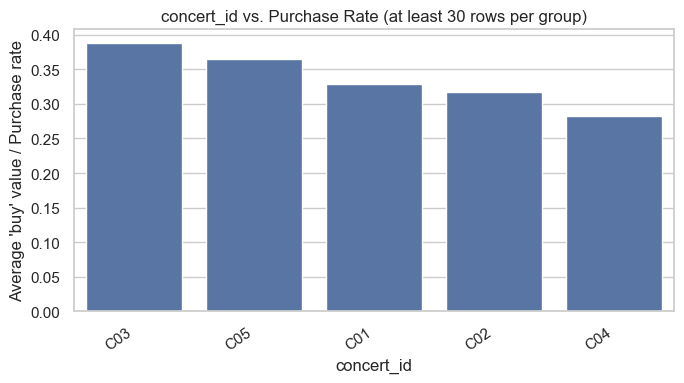


artist_name：


,rows,buy_rate
artist_name,,
Taylor Swift,6000,38.82%
SZA,6000,36.47%
Kendrick Lamar,6000,32.92%
Olivia Rodrigo,6000,31.67%
Tame Impala,6000,28.23%


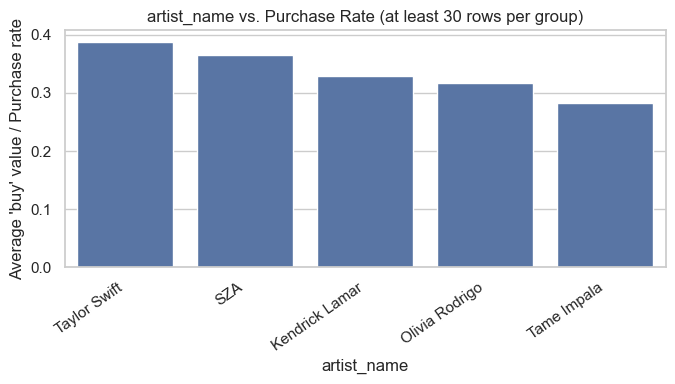


venue_city：


,rows,buy_rate
venue_city,,
Bordeaux,6000,38.82%
Nantes,6000,36.47%
Paris,6000,32.92%
Lyon,6000,31.67%
Lille,6000,28.23%


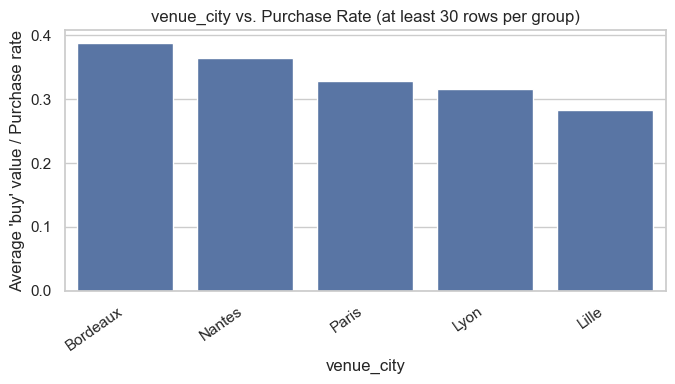


home_city：


,rows,buy_rate
home_city,,
Rennes,2395,36.20%
Nantes,2970,35.12%
Paris,8430,34.21%
Lyon,4410,33.97%
Bordeaux,3650,33.53%
Lille,3015,32.24%
Toulouse,3130,31.44%
Strasbourg,2000,30.70%


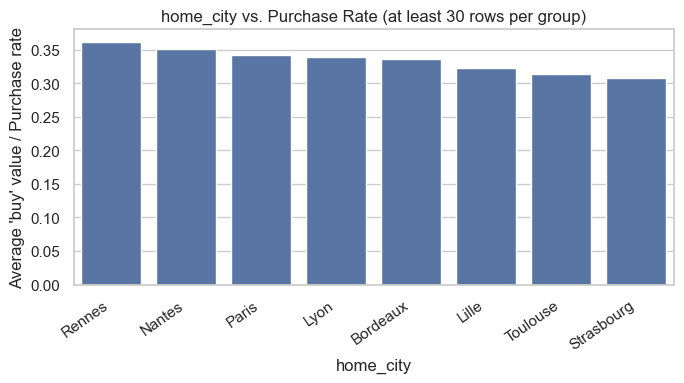


education：


,rows,buy_rate
education,,
postgraduate,6865,34.14%
undergraduate,13190,33.65%
secondary,9945,33.22%


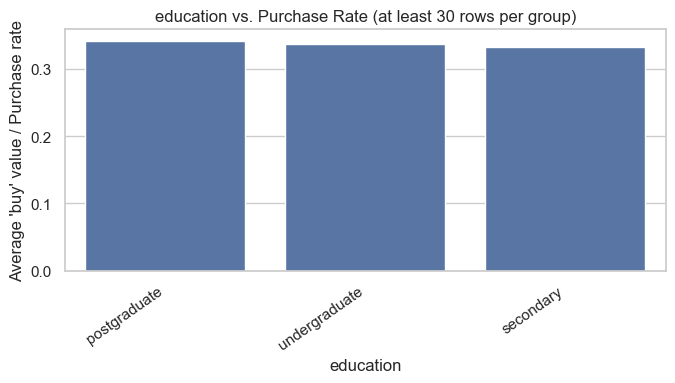


stated_favourite_genre：


,rows,buy_rate
stated_favourite_genre,,
pop,2330,40.56%
rnb_soul,2395,36.49%
pop_rock,2235,34.72%
nan,4625,34.57%
hip_hop,2485,34.25%
alternative,2480,33.71%
folk_country,2370,33.59%
jazz_funk,2320,32.28%
electronic,2255,31.84%


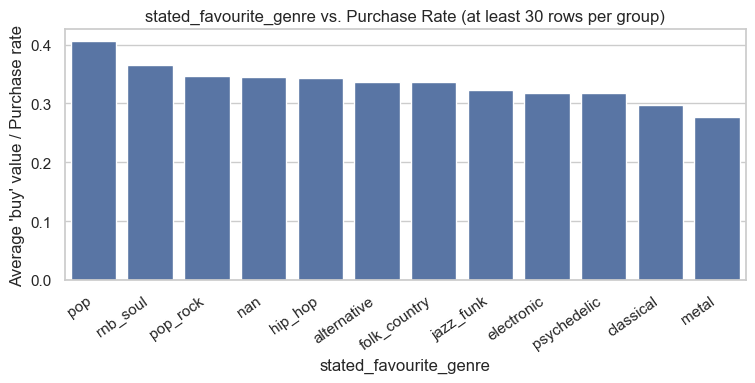


spending_capacity_band：


,rows,buy_rate
spending_capacity_band,,
5,6420,40.55%
4,5055,37.84%
3,6370,34.55%
2,5795,30.84%
1,6360,24.87%


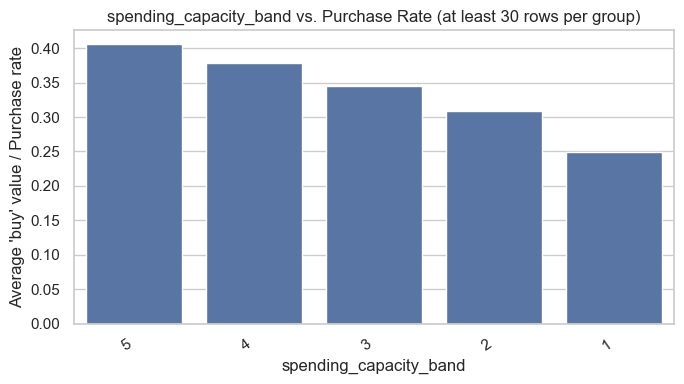


wishlisted：


,rows,buy_rate
wishlisted,,
1,4866,42.70%
0,25134,31.86%


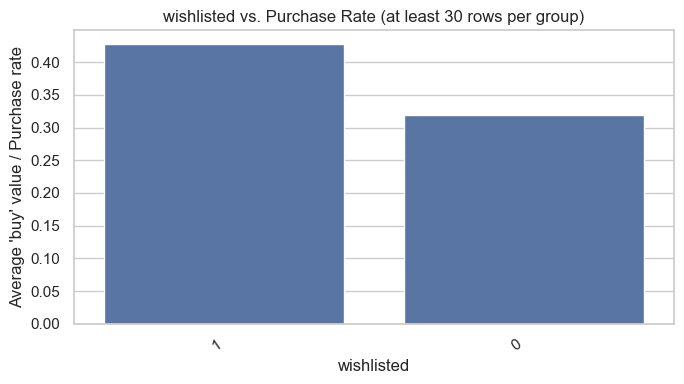


first_timer：


,rows,buy_rate
first_timer,,
1,8240,36.69%
0,21760,32.46%


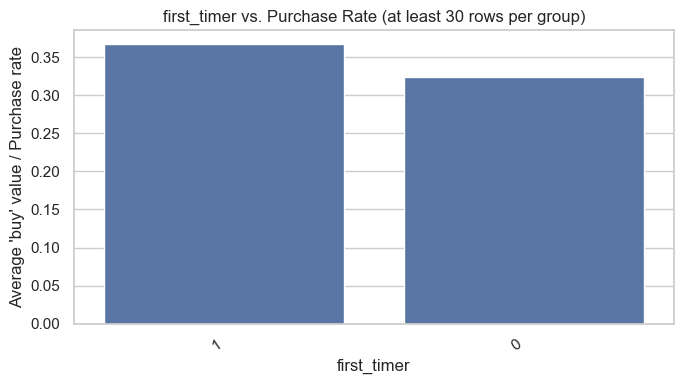

In [31]:
if "buy" in df:
    cat_candidates = [c for c in ["concert_id", "artist_name", "venue_city", "home_city", "education", "stated_favourite_genre", "spending_capacity_band", "wishlisted", "first_timer"] if c in df]
    for col in cat_candidates:
        summary = df.groupby(col, dropna=False).agg(rows=("buy", "size"), buy_rate=("buy", "mean")).query("rows >= 30").sort_values("buy_rate", ascending=False)
        print(f"\n{col}：")
        display(summary.style.format({"buy_rate": "{:.2%}"}))
        if len(summary):
            plt.figure(figsize=(max(7, min(14, 0.65 * len(summary))), 4))
            sns.barplot(x=summary.index.astype(str), y=summary["buy_rate"], color="#4C72B0")
            plt.title(f"{col} vs. Purchase Rate (at least 30 rows per group)")
            plt.ylabel("Average 'buy' value / Purchase rate")
            plt.xlabel(col)
            plt.xticks(rotation=35, ha="right")
            plt.tight_layout()
            plt.show()

## 11. Analyzing Purchase Rates via Binning of Continuous Variables

By partitioning a continuous variable into several groups based on quantiles, one can observe whether a monotonic or non-linear relationship exists. For instance, the impact of price may not be linear, and the number of page visits might exhibit a saturation effect. Binning plots are intended for exploratory analysis; the original continuous values ​​can be retained for formal modeling.


age Quantile Binning:


,rows,buy_rate
age,,
"(17.999, 27.0]",6380,33.20%
"(27.0, 37.0]",6140,33.26%
"(37.0, 46.0]",5770,34.14%
"(46.0, 56.0]",6100,33.39%
"(56.0, 65.0]",5610,34.21%


C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


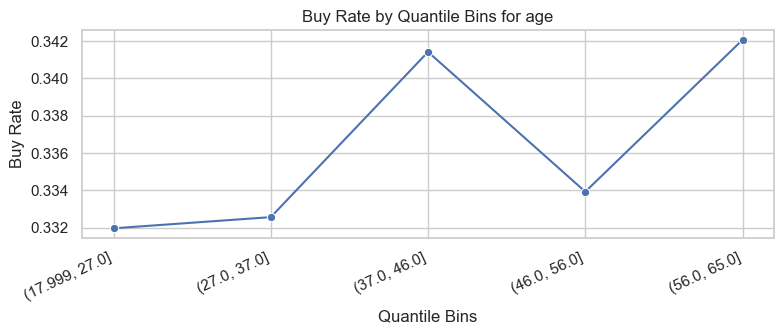


ticket_price Quantile Binning:


,rows,buy_rate
ticket_price,,
"(59.999, 75.0]",6262,30.28%
"(75.0, 85.0]",6279,35.77%
"(85.0, 105.0]",7831,32.61%
"(105.0, 118.75]",3957,36.54%
"(118.75, 175.0]",5671,34.28%


C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


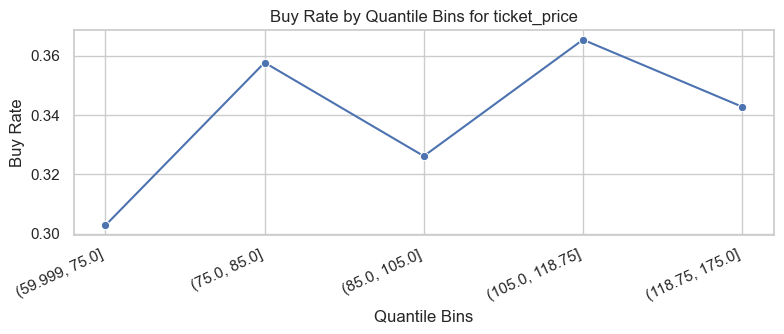


event_page_visits_7d Quantile Binning:


,rows,buy_rate
event_page_visits_7d,,
"(-0.001, 1.0]",25433,32.06%
"(1.0, 6.0]",3704,44.95%


C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


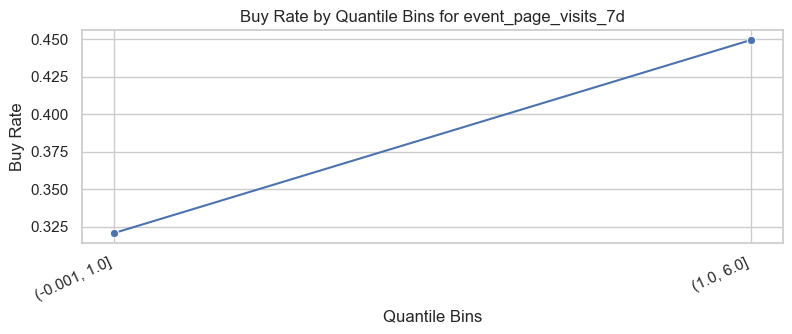


past_purchase_count Quantile Binning:


,rows,buy_rate
past_purchase_count,,
"(-0.001, 2.0]",12695,34.87%
"(2.0, 4.0]",9555,33.00%
"(4.0, 5.0]",3640,32.12%
"(5.0, 13.0]",4110,32.53%


C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


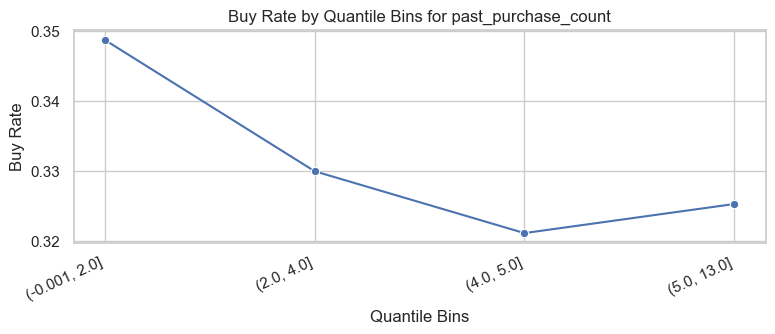


usual_booking_lead_days Quantile Binning:


,rows,buy_rate
usual_booking_lead_days,,
"(3.499, 28.0]",4400,30.68%
"(28.0, 42.0]",4305,32.92%
"(42.0, 59.0]",4420,34.10%
"(59.0, 90.0]",4300,34.40%
"(90.0, 497.0]",4335,30.22%


C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


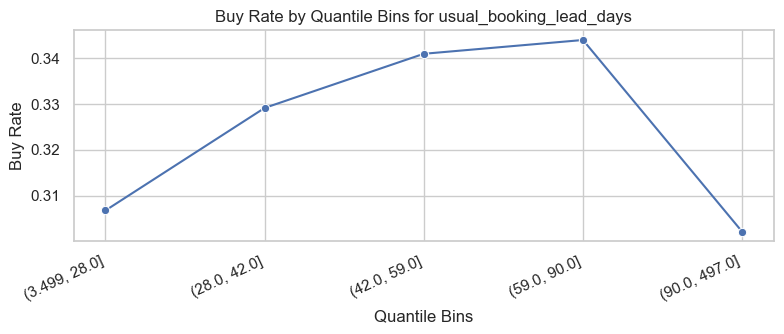

In [35]:
bin_cols = [c for c in ["age", "ticket_price", "event_page_visits_7d", "past_purchase_count", "usual_booking_lead_days"] if c in df]
if "buy" in df:
    for col in bin_cols:
        valid = df[[col, "buy"]].dropna()
        if valid[col].nunique() >= 3:
            try:
                bins = pd.qcut(valid[col], q=min(5, valid[col].nunique()), duplicates="drop")
                summary = valid.groupby(bins, observed=False)["buy"].agg(["size", "mean"])
                print(f"\n{col} Quantile Binning:")
                display(summary.rename(columns={"size": "rows", "mean": "buy_rate"}).style.format({"buy_rate": "{:.2%}"}))
                plt.figure(figsize=(8, 3.5))
                sns.lineplot(x=np.arange(len(summary)), y=summary["mean"].values, marker="o")
                plt.xticks(np.arange(len(summary)), summary.index.astype(str), rotation=25, ha="right")
                plt.title(f"Buy Rate by Quantile Bins for {col}")
                plt.ylabel("Buy Rate")
                plt.xlabel("Quantile Bins")
                plt.tight_layout()
                plt.show()
            except ValueError as e:
                print(f"Could not bin {col}: {e}")

## 13. Feature Engineering Examples: Distance, Date, and Price

The following demonstrates how to derive more interpretable variables from existing fields. Distance is approximated using the Haversine formula (great-circle distance). Total fare is calculated as the discounted fare plus the booking fee—please verify this against the discount definitions provided in the assignment's data dictionary. If the discount rules apply differently (e.g., to the total price or specific fees), the formula should be adjusted accordingly.

In [19]:
# Haversine: Spherical distance between two sets of latitude and longitude coordinates (in degrees), measured in km
# def haversine_km(lat1, lon1, lat2, lon2):
#     earth_radius_km = 6371.0
#     lat1, lon1, lat2, lon2 = [np.radians(x) for x in (lat1, lon1, lat2, lon2)]
#     dlat = lat2 - lat1
#     dlon = lon2 - lon1
#     a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
#     return 2 * earth_radius_km * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

# if {"home_lat", "home_lon", "venue_lat", "venue_lon"}.issubset(df.columns):
#     df["home_to_venue_km"] = haversine_km(df["home_lat"], df["home_lon"], df["venue_lat"], df["venue_lon"])

# if {"ticket_price", "booking_fee", "discount_pct"}.issubset(df.columns):
#     df["estimated_total_price"] = df["ticket_price"] * (1 - df["discount_pct"] / 100) + df["booking_fee"]

# if {"concert_at", "prediction_at"}.issubset(df.columns):
#     df["days_until_concert"] = (df["concert_at"] - df["prediction_at"]).dt.total_seconds() / 86400

# if {"home_city", "venue_city"}.issubset(df.columns):
#     df["same_city"] = (df["home_city"] == df["venue_city"]).astype("int8")

# engineered = [c for c in ["home_to_venue_km", "estimated_total_price", "days_until_concert", "same_city"] if c in df]
# display(df[engineered].describe().T if engineered else "Insufficient fields available to generate example features.")
# if "home_to_venue_km" in df and "buy" in df:
#     plt.figure(figsize=(8, 4))
#     sns.boxplot(data=df, x="buy", y="home_to_venue_km", showfliers=False)
#     plt.title("Distance from Residence to Venue vs. Purchase Behavior")
#     plt.ylabel("Distance (km)")
#     plt.show()

In [26]:
df[df['discount_pct'] == 0].shape

(19460, 32)

In [29]:
df[df['home_city'] == 'Paris'].sample(10)

,row_id,user_id,music_app_user_id,age,education,spending_capacity_band,home_city,home_lat,home_lon,stated_favourite_genre,...,sale_opened_at,prediction_at,ticket_price,booking_fee,discount_pct,event_page_visits_7d,wishlisted,travel_search_city,travel_search_arrival,buy
25083,R31296EA3,U1E9210D8,M13339E92,36,undergraduate,1,Paris,48.857,2.352,metal,...,2026-09-28 00:00:00+00:00,2026-10-01 00:00:00+00:00,93.75,10.62,0,2.0,0,NaN,NaT,0
1210,R355F4CBC,U216CF2B8,M02D9E605,35,undergraduate,4,Paris,48.857,2.352,NaN,...,2026-09-28 00:00:00+00:00,2026-10-01 00:00:00+00:00,105.00,11.30,10,1.0,0,NaN,NaT,1
15307,R0F7ED5AC,U139AA87D,M3B1F4595,42,postgraduate,2,Paris,48.857,2.352,hip_hop,...,2026-09-28 00:00:00+00:00,2026-10-01 00:00:00+00:00,75.00,9.50,10,2.0,0,NaN,NaT,0
22369,R2EFD0016,U13B80596,M34C988EB,65,postgraduate,2,Paris,48.857,2.352,pop,...,2026-09-28 00:00:00+00:00,2026-10-01 00:00:00+00:00,68.00,9.08,0,0.0,1,NaN,NaT,1
22420,R3758AB45,U22E60BB3,M179CCEEC,24,undergraduate,4,Paris,48.857,2.352,NaN,...,2026-09-28 00:00:00+00:00,2026-10-01 00:00:00+00:00,105.00,11.30,0,0.0,0,NaN,NaT,0
19688,R2B165EFA,U2036DB09,M03A26A23,42,postgraduate,5,Paris,48.857,2.352,alternative,...,2026-09-28 00:00:00+00:00,2026-10-01 00:00:00+00:00,105.00,11.30,0,1.0,0,NaN,NaT,0
564,R01F15F5C,U17F4128B,M1C43AEE6,38,undergraduate,3,Paris,48.857,2.352,hip_hop,...,2026-09-28 00:00:00+00:00,2026-10-01 00:00:00+00:00,95.00,10.70,0,1.0,0,NaN,NaT,0
8637,R24E4E210,U3B2AEAC5,M0E1B61F0,42,secondary,1,Paris,48.857,2.352,classical,...,2026-09-28 00:00:00+00:00,2026-10-01 00:00:00+00:00,105.00,11.30,10,0.0,1,NaN,NaT,0
8811,R25985BA3,U12E32287,M34BEE43D,27,postgraduate,4,Paris,48.857,2.352,folk_country,...,2026-09-28 00:00:00+00:00,2026-10-01 00:00:00+00:00,112.00,11.72,0,1.0,0,Bordeaux,2026-11-27 00:00:00+00:00,1
12273,R0570AD50,U014844BF,M25135A9F,54,secondary,4,Paris,48.857,2.352,pop_rock,...,2026-09-28 00:00:00+00:00,2026-10-01 00:00:00+00:00,93.75,10.62,10,1.0,0,NaN,NaT,0


In [31]:
df.groupby("home_city")[
    ["home_lat", "home_lon"]
].nunique()


,home_lat,home_lon
home_city,,
Bordeaux,1,1
Lille,1,1
Lyon,1,1
Nantes,1,1
Paris,1,1
Rennes,1,1
Strasbourg,1,1
Toulouse,1,1
